# 03 Build a CNN from Scratch

## Goal

Build a compact convolutional neural network (CNN) for CIFAR-10. The objective is to understand the building blocks, not to achieve state-of-the-art accuracy.

A CNN typically uses:
- `Conv2D` layers to learn spatial patterns.
- `MaxPooling2D` to reduce spatial dimensions.
- `Flatten` or global pooling to prepare features for classification.
- `Dense` layers to produce class scores.


In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10

SEED = 42
keras.utils.set_random_seed(SEED)

(x_train_all, y_train_all), (x_test_raw, y_test_raw) = cifar10.load_data()
y_train_all = y_train_all.squeeze()
y_test = y_test_raw.squeeze()

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(x_train_all))
val_idx, train_idx = idx[:5000], idx[5000:]

x_train = x_train_all[train_idx].astype("float32") / 255.0
y_train = y_train_all[train_idx]
x_val = x_train_all[val_idx].astype("float32") / 255.0
y_val = y_train_all[val_idx]

train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(len(x_train), seed=SEED)
    .batch(64).prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(64).prefetch(tf.data.AUTOTUNE)
)

os.makedirs("../artifacts", exist_ok=True)


2026-11-01 18:01:35.068319: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-01 18:01:35.196356: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793556095.258729    1829 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793556095.275870    1829 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793556095.405332    1829 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

## 1. Define the model

The final layer has 10 outputs—one score per class. We use `SparseCategoricalCrossentropy` because labels are integer class IDs rather than one-hot vectors.


In [2]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="cifar10_small_cnn")

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()


Model: "cifar10_small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

## 2. Train the model

Start with a small number of epochs so the notebook remains practical for a workshop. Watch training and validation accuracy: if training improves while validation stops improving or worsens, the model may be overfitting.


In [3]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
)

model.save("../artifacts/cifar10_cnn.keras")
print("Saved: ../artifacts/cifar10_cnn.keras")


Epoch 1/20


/home/ashtosh/miniconda3/envs/cubesat-ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793556110.329656    2066 service.cc:152] XLA service 0x7a15b4018710 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793556110.329734    2066 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2026-11-01 18:01:50.368034: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793556110.541157    2066 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-11-01 18:01:51.188868: I external/local_xla/xla/stream_e

 37/704 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.1199 - loss: 2.2912

I0000 00:00:1793556115.162765    2066 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


692/704 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2801 - loss: 1.8715

2026-11-01 18:01:58.729178: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_524', 8 bytes spill stores, 8 bytes spill loads



704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2808 - loss: 1.8700

2026-11-01 18:02:00.784724: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_79', 4 bytes spill stores, 4 bytes spill loads



704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.2808 - loss: 1.8700 - val_accuracy: 0.3796 - val_loss: 1.6539
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3964 - loss: 1.6080 - val_accuracy: 0.4460 - val_loss: 1.5029
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4583 - loss: 1.4642 - val_accuracy: 0.4676 - val_loss: 1.4126
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5000 - loss: 1.3652 - val_accuracy: 0.5248 - val_loss: 1.3147
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5328 - loss: 1.2887 - val_accuracy: 0.5450 - val_loss: 1.2282
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.5540 - loss: 1.2314 - val_accuracy: 0.5342 - val_loss: 1.2916
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5775 - loss: 1.1787 - val_accuracy: 0.5892 - val_loss: 1.1122
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5904 - loss: 1.1409 - val_accuracy: 0.5936 - 

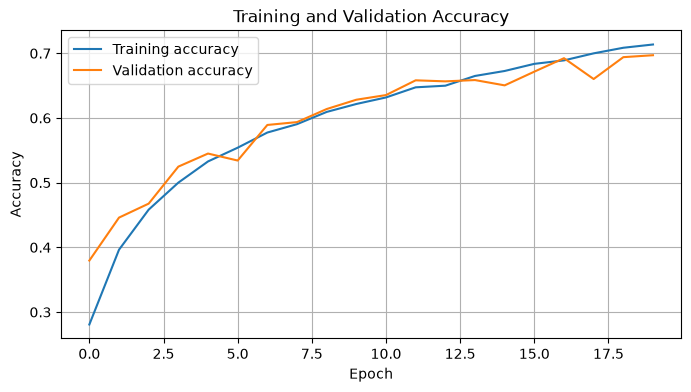

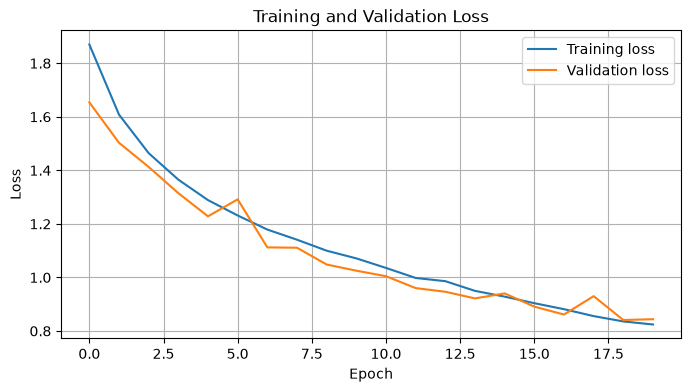

In [4]:
import matplotlib.pyplot as plt

# Accuracy plot
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss plot
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Reflection

1. What does a convolution learn?
2. Why does pooling reduce spatial dimensions?
3. Why are there 10 outputs?
4. What do the training and validation curves suggest?
5. Why is this CNN a useful baseline even if its accuracy is modest?

**Next:** compare this baseline with transfer learning using MobileNetV2.
